In [1]:
# Import the libraries required for statistical analysis and visualisation

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.stats.multitest import multipletests

In [3]:
# Import the libraries required for hypothesis testing
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.stats.multitest import multipletests

# Load the final combined dataset
df = pd.read_csv('Final_Dataset_AIBD (1).csv')

# Display the first five rows
display(df.head())

/tmp/ipykernel_803/1822147482.py:11: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Final_Dataset_AIBD (1).csv')


,Unnamed: 0.1,Unnamed: 0,Age,Gender,ICU,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1,...,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,TBX3,SCD5,H2AP
0,0,C1,39,male,no,0.41,0.29,3.50,83.13,793.95,...,464.73,24.29,55.98,1.79,1.93,2.26,10.80,0.00,0.89,0.0
1,1,C2,63,male,no,0.38,0.93,4.37,94.44,990.27,...,177.66,35.44,99.14,1.74,1.69,2.61,6.19,0.00,1.13,0.0
2,2,C3,33,male,no,0.39,0.10,2.24,41.24,719.21,...,393.77,6.81,12.31,1.86,0.38,6.12,3.59,0.00,0.62,0.0
3,3,C4,49,male,no,0.56,0.19,7.87,123.22,804.48,...,256.23,24.50,122.51,3.43,1.82,5.01,9.48,0.01,1.59,0.0
4,4,C5,49,male,no,0.45,0.44,1.92,72.72,505.98,...,482.63,15.10,44.62,0.51,0.21,3.15,4.39,0.00,0.65,0.0


In [4]:
# Check the dimensions of the dataset
print("Dataset dimensions:", df.shape)

# Check the data types of the first few columns
print("\nData types:")
print(df.dtypes.iloc[:10])

# Check the unique values in the clinical columns
print("\nUnique values in Gender:")
print(df['Gender'].unique())

print("\nUnique values in ICU:")
print(df['ICU'].unique())

# Check for missing values in the clinical columns
print("\nMissing values in clinical columns:")
print(df.iloc[:, :6].isnull().sum())

# Check whether there are any duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Dataset dimensions: (185, 17726)

Data types:
Unnamed: 0.1      int64
Unnamed: 0       object
Age               int64
Gender           object
ICU              object
RUNDC3A         float64
DEPDC1          float64
BICDL1          float64
ATP5PB          float64
COTL1           float64
dtype: object

Unique values in Gender:
['male' 'female' 'unknown']

Unique values in ICU:
['no' 'yes' nan]

Missing values in clinical columns:
Unnamed: 0.1     0
Unnamed: 0       0
Age              0
Gender           0
ICU             85
RUNDC3A          0
dtype: int64

Number of duplicate rows: 0


In [5]:
# Check the number of samples in each clinical category

print("Gender distribution:")
print(df['Gender'].value_counts(dropna=False))

print("\nICU distribution:")
print(df['ICU'].value_counts(dropna=False))

# Inspect sample IDs to understand how the groups are labelled
print("\nFirst 20 sample IDs:")
print(df['Unnamed: 0'].head(20).tolist())

print("\nLast 20 sample IDs:")
print(df['Unnamed: 0'].tail(20).tolist())

# Check the number of unique sample IDs
print("\nNumber of unique sample IDs:", df['Unnamed: 0'].nunique())

Gender distribution:
Gender
male       104
female      80
unknown      1
Name: count, dtype: int64

ICU distribution:
ICU
NaN    85
no     50
yes    50
Name: count, dtype: int64

First 20 sample IDs:
['C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20']

Last 20 sample IDs:
['NC66', 'NC67', 'NC68', 'NC69', 'NC70', 'NC71', 'NC72', 'NC73', 'NC74', 'NC75', 'NC76', 'NC77', 'NC78', 'NC79', 'NC80', 'NC81', 'NC82', 'NC83', 'NC84', 'NC85']

Number of unique sample IDs: 185


In [6]:
# Separate samples based on their sample ID prefixes

df['Sample_Group'] = df['Unnamed: 0'].apply(
    lambda x: 'C' if str(x).startswith('C') and not str(x).startswith('NC')
    else 'NC' if str(x).startswith('NC')
    else 'Other'
)

# Count the number of samples in each group
print("Sample distribution:")
print(df['Sample_Group'].value_counts())

# Check ICU distribution within each sample group
print("\nICU distribution by sample group:")
print(pd.crosstab(df['Sample_Group'], df['ICU'], dropna=False))

Sample distribution:
Sample_Group
C     100
NC     85
Name: count, dtype: int64

ICU distribution by sample group:
ICU           no  yes  NaN
Sample_Group              
C             50   50    0
NC             0    0   85


In [7]:
# Remove the unnecessary index columns from the dataset
df = df.drop(columns=['Unnamed: 0.1'])

# Rename the sample ID column for easier reference
df = df.rename(columns={'Unnamed: 0': 'Sample_ID'})

# Create a disease group column based on the sample ID prefix
# C represents COVID-positive and NC represents COVID-negative
df['Disease_Status'] = df['Sample_ID'].apply(
    lambda x: 'COVID' if str(x).startswith('C') and not str(x).startswith('NC')
    else 'Non-COVID' if str(x).startswith('NC')
    else 'Other'
)

# Display the number of samples in each disease group
print("Disease group distribution:")
print(df['Disease_Status'].value_counts())

# Display the first few rows to verify the changes
display(df[['Sample_ID', 'Age', 'Gender', 'ICU', 'Disease_Status']].head())

Disease group distribution:
Disease_Status
COVID        100
Non-COVID     85
Name: count, dtype: int64


,Sample_ID,Age,Gender,ICU,Disease_Status
0,C1,39,male,no,COVID
1,C2,63,male,no,COVID
2,C3,33,male,no,COVID
3,C4,49,male,no,COVID
4,C5,49,male,no,COVID


In [9]:
# Identify all columns containing sample and clinical information
clinical_columns = [
    'Sample_ID', 'Age', 'Gender', 'ICU',
    'Disease_Status', 'Sample_Group'
]

# Select only the gene-expression columns
gene_columns = [
    col for col in df.columns
    if col not in clinical_columns
]

# Check the number of genes
print("Number of genes:", len(gene_columns))

# Verify that all gene-expression columns are numeric
print("\nNon-numeric gene columns:")
print(df[gene_columns].select_dtypes(exclude='number').columns.tolist())

# Check for missing values
print("\nTotal missing expression values:",
      df[gene_columns].isnull().sum().sum())

# Display a few gene-expression values
display(df[gene_columns].head())

Number of genes: 17721

Non-numeric gene columns:
[]

Total missing expression values: 0


,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1,TRIM40,EFNB3,AREL1,DNHD1,CFAP97,...,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,TBX3,SCD5,H2AP
0,0.41,0.29,3.50,83.13,793.95,0.13,0.00,30.10,1.69,5.22,...,464.73,24.29,55.98,1.79,1.93,2.26,10.80,0.00,0.89,0.0
1,0.38,0.93,4.37,94.44,990.27,1.03,0.00,28.02,1.09,4.58,...,177.66,35.44,99.14,1.74,1.69,2.61,6.19,0.00,1.13,0.0
2,0.39,0.10,2.24,41.24,719.21,0.00,0.00,22.51,0.66,1.19,...,393.77,6.81,12.31,1.86,0.38,6.12,3.59,0.00,0.62,0.0
3,0.56,0.19,7.87,123.22,804.48,0.30,0.02,30.87,1.86,7.71,...,256.23,24.50,122.51,3.43,1.82,5.01,9.48,0.01,1.59,0.0
4,0.45,0.44,1.92,72.72,505.98,0.12,0.02,28.35,0.64,2.59,...,482.63,15.10,44.62,0.51,0.21,3.15,4.39,0.00,0.65,0.0


Expression value summary:
        RUNDC3A    DEPDC1     BICDL1      ATP5PB        COTL1    TRIM40  \
min    0.000000  0.000000  -0.521799   34.890000   273.940000  0.000000   
25%    0.560000  0.040779   0.840000   55.860000   687.180000  0.060000   
50%    1.057003  0.160000   2.180000   68.486990   824.589451  0.170000   
mean   1.697613  0.312946   2.948252   70.044994   854.061530  0.260237   
75%    1.820000  0.480000   4.291440   81.720000  1006.200000  0.370000   
max   13.940000  1.830000  14.200000  128.020000  1488.680547  1.630000   

         EFNB3      AREL1     DNHD1     CFAP97  ...        CCR1       DMTN  \
min   0.000000   3.090786  0.060000  -0.433911  ...    6.080000   3.730000   
25%   0.000000  14.239151  0.368983   1.060000  ...   45.390000  14.931269   
50%   0.000000  22.010000  0.658472   2.130000  ...   86.830000  19.880872   
mean  0.002909  22.015811  0.784595   2.735815  ...  112.577335  22.462800   
75%   0.000026  29.370000  1.040000   3.750000  ...  145.0

,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1
count,185.000000,185.000000,185.000000,185.000000,185.000000
mean,1.697613,0.312946,2.948252,70.044994,854.061530
std,2.224131,0.362547,2.791790,18.629055,222.795501
min,0.000000,0.000000,-0.521799,34.890000,273.940000
25%,0.560000,0.040779,0.840000,55.860000,687.180000
50%,1.057003,0.160000,2.180000,68.486990,824.589451
75%,1.820000,0.480000,4.291440,81.720000,1006.200000
max,13.940000,1.830000,14.200000,128.020000,1488.680547


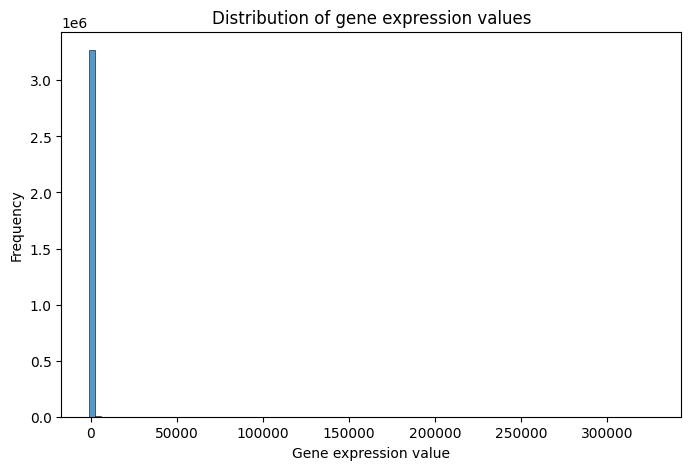

In [10]:
# Check the overall distribution of gene-expression values

print("Expression value summary:")
print(df[gene_columns].describe().loc[['min', '25%', '50%', 'mean', '75%', 'max']])

# Examine the distribution of expression values for a few genes
selected_genes = gene_columns[:5]

print("\nExpression summary for the first five genes:")
display(df[selected_genes].describe())

# Plot the distribution of expression values across all genes and samples
plt.figure(figsize=(8, 5))
sns.histplot(df[gene_columns].values.flatten(), bins=100, kde=False)

plt.xlabel("Gene expression value")
plt.ylabel("Frequency")
plt.title("Distribution of gene expression values")
plt.show()

Negative expression values:
COVID: 0
Non-COVID: 26883

COVID expression range:
Minimum: 0.0
Maximum: 326585.43

Non-COVID expression range:
Minimum: -639.8985945641908
Maximum: 319884.0462803608


/tmp/ipykernel_803/70197077.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


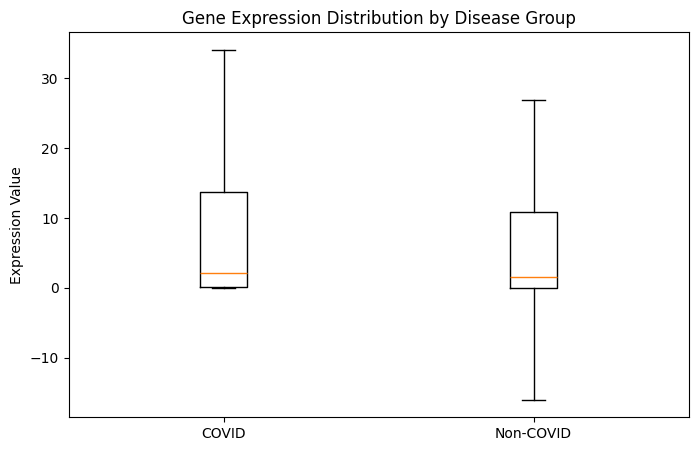

In [14]:
# Check the number of negative expression values in each group
print("Negative expression values:")
print("COVID:", (covid_data < 0).sum().sum())
print("Non-COVID:", (non_covid_data < 0).sum().sum())

# Check the minimum and maximum expression values in each group
print("\nCOVID expression range:")
print("Minimum:", covid_data.min().min())
print("Maximum:", covid_data.max().max())

print("\nNon-COVID expression range:")
print("Minimum:", non_covid_data.min().min())
print("Maximum:", non_covid_data.max().max())

# Compare the expression distributions between the two groups
plt.figure(figsize=(8, 5))

plt.boxplot(
    [covid_data.values.flatten(), non_covid_data.values.flatten()],
    labels=['COVID', 'Non-COVID'],
    showfliers=False
)

plt.title("Gene Expression Distribution by Disease Group")
plt.ylabel("Expression Value")
plt.show()

In [15]:
# Count negative expression values for each gene
negative_per_gene = (non_covid_data < 0).sum()

# Identify genes containing at least one negative value
genes_with_negative_values = negative_per_gene[negative_per_gene > 0]

print("Number of genes with negative values:",
      len(genes_with_negative_values))

print("\nTop 20 genes with the most negative values:")
print(genes_with_negative_values.sort_values(ascending=False).head(20))

# Count negative expression values for each non-COVID sample
negative_per_sample = (non_covid_data < 0).sum(axis=1)

print("\nNegative values per non-COVID sample:")
print(negative_per_sample.describe())

# Display samples with the highest number of negative values
print("\nSamples with the most negative values:")
print(negative_per_sample.sort_values(ascending=False).head(10))


Number of genes with negative values: 2194

Top 20 genes with the most negative values:
MEIOB        56
RHOXF2B      56
TDO2         56
RS1          56
SPINK9       56
TFDP3        56
FNDC1        56
SERPINB11    56
CRYAB        56
STC1         56
PCDHGB1      56
SCEL         56
TTLL6        56
TMEM151B     56
SLC22A25     56
SMYD1        56
C9           56
KRT71        56
PKNOX2       56
IFNL3        56
dtype: int64

Negative values per non-COVID sample:
count      85.000000
mean      316.270588
std       276.480017
min         0.000000
25%         0.000000
50%       294.000000
75%       492.000000
max      1140.000000
dtype: float64

Samples with the most negative values:
136    1140
176     949
134     855
141     839
140     788
180     774
135     723
147     723
133     704
156     664
dtype: int64


NC1-NC26:
       RUNDC3A  DEPDC1     BICDL1     ATP5PB        COTL1    TRIM40     EFNB3  \
min   0.290000   0.000   0.240000  43.630000   665.880000  0.000000  0.000000   
50%   1.535000   0.045   2.165000  60.520000  1008.420000  0.110000  0.000000   
mean  1.566923   0.075   2.938077  62.977692  1007.546154  0.137692  0.001154   
max   5.160000   0.380  12.450000  85.210000  1402.550000  0.600000  0.030000   

       AREL1  DNHD1    CFAP97  ...        CCR1       DMTN     CAVIN2  \
min    4.050  0.150  0.260000  ...   23.380000   6.530000   7.070000   
50%   18.465  0.485  1.315000  ...   47.850000  18.290000  19.790000   
mean  17.995  0.600  1.886538  ...   76.643846  18.891154  26.280769   
max   35.540  1.730  7.160000  ...  211.230000  46.450000  61.680000   

        IZUMO4  SEPTIN10    ZCWPW1   DENND4C      TBX3      SCD5  H2AP  
min   0.630000  0.150000  1.040000  0.340000  0.000000  0.080000   0.0  
50%   2.480000  0.625000  4.275000  1.835000  0.000000  0.390000   0.0  
mean

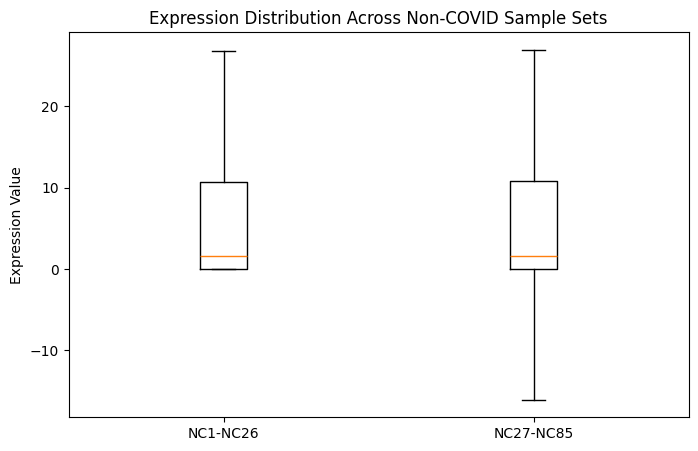

In [16]:
# Separate the non-COVID samples into the two suspected dataset groups
nc_original = non_covid_data.loc[
    df.loc[non_covid_data.index, 'Sample_ID'].isin(
        [f'NC{i}' for i in range(1, 27)]
    )
]

nc_additional = non_covid_data.loc[
    df.loc[non_covid_data.index, 'Sample_ID'].isin(
        [f'NC{i}' for i in range(27, 86)]
    )
]

# Compare their expression distributions
print("NC1-NC26:")
print(nc_original.describe().loc[['min', '50%', 'mean', 'max']])

print("\nNC27-NC85:")
print(nc_additional.describe().loc[['min', '50%', 'mean', 'max']])

# Count negative values in each set
print("\nNegative expression values:")
print("NC1-NC26:", (nc_original < 0).sum().sum())
print("NC27-NC85:", (nc_additional < 0).sum().sum())

# Compare the median expression across samples
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        nc_original.values.flatten(),
        nc_additional.values.flatten()
    ],
    tick_labels=['NC1-NC26', 'NC27-NC85'],
    showfliers=False
)

plt.title("Expression Distribution Across Non-COVID Sample Sets")
plt.ylabel("Expression Value")
plt.show()

In [17]:
# Compare the mean expression of every gene between the two subsets
mean_nc_original = nc_original.mean()
mean_nc_additional = nc_additional.mean()

mean_difference = (mean_nc_original - mean_nc_additional).abs()

print("Number of genes with exactly equal means:",
      (mean_difference == 0).sum())

print("Maximum absolute difference between gene means:",
      mean_difference.max())

print("\nMean difference summary:")
print(mean_difference.describe())

# Check that the two subsets contain the intended samples
print("\nSample IDs in NC1-NC26:")
print(df.loc[nc_original.index, 'Sample_ID'].tolist())

print("\nSample IDs in NC27-NC85:")
print(df.loc[nc_additional.index, 'Sample_ID'].tolist())

Number of genes with exactly equal means: 5655
Maximum absolute difference between gene means: 1.4551915228366852e-11

Mean difference summary:
count    1.772100e+04
mean     5.878891e-15
std      1.262816e-13
min      0.000000e+00
25%      0.000000e+00
50%      5.551115e-17
75%      8.881784e-16
max      1.455192e-11
dtype: float64

Sample IDs in NC1-NC26:
['NC1', 'NC2', 'NC3', 'NC4', 'NC5', 'NC6', 'NC7', 'NC8', 'NC9', 'NC10', 'NC11', 'NC12', 'NC13', 'NC14', 'NC15', 'NC16', 'NC17', 'NC18', 'NC19', 'NC20', 'NC21', 'NC22', 'NC23', 'NC24', 'NC25', 'NC26']

Sample IDs in NC27-NC85:
['NC27', 'NC28', 'NC29', 'NC30', 'NC31', 'NC32', 'NC33', 'NC34', 'NC35', 'NC36', 'NC37', 'NC38', 'NC39', 'NC40', 'NC41', 'NC42', 'NC43', 'NC44', 'NC45', 'NC46', 'NC47', 'NC48', 'NC49', 'NC50', 'NC51', 'NC52', 'NC53', 'NC54', 'NC55', 'NC56', 'NC57', 'NC58', 'NC59', 'NC60', 'NC61', 'NC62', 'NC63', 'NC64', 'NC65', 'NC66', 'NC67', 'NC68', 'NC69', 'NC70', 'NC71', 'NC72', 'NC73', 'NC74', 'NC75', 'NC76', 'NC77', 'NC78

Sample-level summary by subset:


Mean_Expression                           Median_Expression          \
                     mean     std      min      max              mean     std   
Subset                                                                          
NC1-NC26          55.5661  0.1555  55.1617  55.7643            1.7623  0.6816   
NC27-NC85         55.5661  7.2983  43.6373  74.2589            1.7266  0.6456   

                          Std_Expression                                 \
              min     max           mean       std       min        max   
Subset                                                                    
NC1-NC26   0.5800  3.2500      1271.3916  376.6082  609.2276  2399.9964   
NC27-NC85  0.7019  3.1736      1232.6998  496.1348  636.1464  2979.6740   

          Negative_Values                       
                     mean       std  min   max  
Subset                                          
NC1-NC26           0.0000    0.0000    0     0  
NC27-NC85        455.6441  214.7285  168  1140

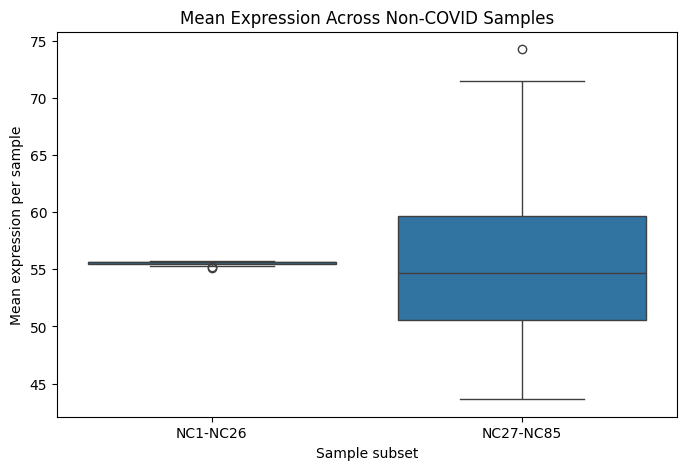

In [18]:
# Calculate a few summary statistics for each non-COVID sample
sample_summary = pd.DataFrame({
    'Sample_ID': df.loc[non_covid_data.index, 'Sample_ID'],
    'Mean_Expression': non_covid_data.mean(axis=1),
    'Median_Expression': non_covid_data.median(axis=1),
    'Std_Expression': non_covid_data.std(axis=1),
    'Negative_Values': (non_covid_data < 0).sum(axis=1)
})

# Label the two subsets
sample_summary['Subset'] = sample_summary['Sample_ID'].apply(
    lambda x: 'NC1-NC26' if int(x[2:]) <= 26 else 'NC27-NC85'
)

print("Sample-level summary by subset:")
display(
    sample_summary.groupby('Subset')[
        ['Mean_Expression', 'Median_Expression',
         'Std_Expression', 'Negative_Values']
    ].agg(['mean', 'std', 'min', 'max']).round(4)
)

# Visualise the sample-level mean expression
plt.figure(figsize=(8, 5))
sns.boxplot(data=sample_summary, x='Subset', y='Mean_Expression')
plt.title("Mean Expression Across Non-COVID Samples")
plt.xlabel("Sample subset")
plt.ylabel("Mean expression per sample")
plt.show()


In [19]:
# Calculate correlations between the non-COVID samples
sample_correlations = non_covid_data.T.corr()

# Separate correlations within and between the two subsets
sample_ids = df.loc[non_covid_data.index, 'Sample_ID']

subset_labels = sample_ids.apply(
    lambda x: 'NC1-NC26' if int(x[2:]) <= 26 else 'NC27-NC85'
)

correlation_groups = pd.DataFrame({
    'Correlation': sample_correlations.values.flatten(),
    'Row_Subset': np.repeat(subset_labels.values, len(subset_labels)),
    'Column_Subset': np.tile(subset_labels.values, len(subset_labels))
})

# Exclude self-correlations
correlation_groups = correlation_groups[
    sample_correlations.values.flatten() < 0.999999
]

print("Average sample correlation:")
display(
    correlation_groups.groupby(
        ['Row_Subset', 'Column_Subset']
    )['Correlation'].agg(['mean', 'std', 'min', 'max']).round(4)
)

Average sample correlation:


mean     std     min     max
Row_Subset Column_Subset                                
NC1-NC26   NC1-NC26       0.8384  0.1405  0.3197  0.9927
           NC27-NC85      0.8738  0.1072  0.3204  0.9956
NC27-NC85  NC1-NC26       0.8738  0.1072  0.3204  0.9956
           NC27-NC85      0.9028  0.0752  0.4602  0.9995

Hypothesis Testing

In [20]:
# Separate patient ages into COVID and non-COVID groups
covid_age = df.loc[df['Disease_Status'] == 'COVID', 'Age']
non_covid_age = df.loc[df['Disease_Status'] == 'Non-COVID', 'Age']

# Perform Welch's independent two-sample t-test
t_stat, p_value = stats.ttest_ind(
    covid_age,
    non_covid_age,
    equal_var=False
)

print("COVID group:")
print("Mean age:", covid_age.mean())
print("Standard deviation:", covid_age.std())

print("\nNon-COVID group:")
print("Mean age:", non_covid_age.mean())
print("Standard deviation:", non_covid_age.std())

print("\nWelch's t-test:")
print("t-statistic:", t_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")

COVID group:
Mean age: 61.06
Standard deviation: 16.242990718299

Non-COVID group:
Mean age: 44.54117647058823
Standard deviation: 25.54293907706546

Welch's t-test:
t-statistic: 5.143547539093271
p-value: 9.073665486535918e-07

Conclusion: Reject the null hypothesis.


In [21]:
# Exclude samples with unknown gender
gender_data = df[df['Gender'].isin(['male', 'female'])]

# Create a contingency table
gender_table = pd.crosstab(
    gender_data['Gender'],
    gender_data['Disease_Status']
)

print("Contingency table:")
display(gender_table)

# Perform the chi-square test of independence
chi2_stat, p_value, dof, expected = stats.chi2_contingency(
    gender_table
)

print("\nExpected frequencies:")
display(pd.DataFrame(
    expected,
    index=gender_table.index,
    columns=gender_table.columns
).round(2))

print("\nChi-square test results:")
print("Chi-square statistic:", chi2_stat)
print("Degrees of freedom:", dof)
print("p-value:", p_value)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")

Contingency table:


Disease_Status,COVID,Non-COVID
Gender,,
female,38,42
male,62,42



Expected frequencies:


Disease_Status,COVID,Non-COVID
Gender,,
female,43.48,36.52
male,56.52,47.48



Chi-square test results:
Chi-square statistic: 2.2090531135531144
Degrees of freedom: 1
p-value: 0.1372028620593243

Conclusion: Fail to reject the null hypothesis.


In [22]:
# Compare age distributions using the Mann-Whitney U test
u_stat, p_value = stats.mannwhitneyu(
    covid_age,
    non_covid_age,
    alternative='two-sided'
)

print("Mann-Whitney U test:")
print("U-statistic:", u_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")

Mann-Whitney U test:
U-statistic: 5838.5
p-value: 1.1974211951736521e-05

Conclusion: Reject the null hypothesis.


In [23]:
# Consider only COVID-positive patients with known ICU status
covid_patients = df[
    (df['Disease_Status'] == 'COVID') &
    (df['ICU'].isin(['yes', 'no']))
]

# Separate ages by ICU status
icu_age = covid_patients.loc[covid_patients['ICU'] == 'yes', 'Age']
non_icu_age = covid_patients.loc[covid_patients['ICU'] == 'no', 'Age']

# Perform Welch's independent two-sample t-test
t_stat, p_value = stats.ttest_ind(
    icu_age,
    non_icu_age,
    equal_var=False
)

print("ICU patients:")
print("Sample size:", len(icu_age))
print("Mean age:", icu_age.mean())
print("Standard deviation:", icu_age.std())

print("\nNon-ICU patients:")
print("Sample size:", len(non_icu_age))
print("Mean age:", non_icu_age.mean())
print("Standard deviation:", non_icu_age.std())

print("\nWelch's t-test:")
print("t-statistic:", t_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")

ICU patients:
Sample size: 50
Mean age: 62.64
Standard deviation: 13.597358687087214

Non-ICU patients:
Sample size: 50
Mean age: 59.48
Standard deviation: 18.52217644900737

Welch's t-test:
t-statistic: 0.9724603668304698
p-value: 0.3334300728129279

Conclusion: Fail to reject the null hypothesis.


In [24]:
# Consider only COVID-positive patients with known gender and ICU status
covid_clinical = df[
    (df['Disease_Status'] == 'COVID') &
    (df['ICU'].isin(['yes', 'no'])) &
    (df['Gender'].isin(['male', 'female']))
]

# Create a contingency table
gender_icu_table = pd.crosstab(
    covid_clinical['Gender'],
    covid_clinical['ICU']
)

print("Observed frequencies:")
display(gender_icu_table)

# Perform chi-square test of independence
chi2, p_value, dof, expected = stats.chi2_contingency(
    gender_icu_table
)

print("\nExpected frequencies:")
print(pd.DataFrame(
    expected,
    index=gender_icu_table.index,
    columns=gender_icu_table.columns
))

print("\nChi-square test:")
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p_value)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")

Observed frequencies:


ICU,no,yes
Gender,,
female,21,17
male,29,33



Expected frequencies:
ICU       no   yes
Gender            
female  19.0  19.0
male    31.0  31.0

Chi-square test:
Chi-square statistic: 0.38200339558573854
Degrees of freedom: 1
p-value: 0.5365329984053668

Conclusion: Fail to reject the null hypothesis.


In [25]:
# Perform a two-sided Mann–Whitney U test
u_stat, p_value = stats.mannwhitneyu(
    icu_age,
    non_icu_age,
    alternative='two-sided'
)

print("Mann–Whitney U test:")
print("U-statistic:", u_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")

Mann–Whitney U test:
U-statistic: 1379.5
p-value: 0.3735319473476466

Conclusion: Fail to reject the null hypothesis.


In [27]:
def perform_f_test(group1, group2, name):
    var1 = group1.var(ddof=1)
    var2 = group2.var(ddof=1)

    # Assign degrees of freedom to the correct numerator and denominator
    if var1 >= var2:
        f_stat = var1 / var2
        df1 = len(group1) - 1
        df2 = len(group2) - 1
    else:
        f_stat = var2 / var1
        df1 = len(group2) - 1
        df2 = len(group1) - 1

    # Two-sided F-test
    p_value = 2 * min(
        stats.f.cdf(f_stat, df1, df2),
        stats.f.sf(f_stat, df1, df2)
    )
    p_value = min(p_value, 1.0)

    print(f"\n{name}")
    print("F-statistic:", f_stat)
    print("Degrees of freedom:", df1, df2)
    print("p-value:", p_value)

    if p_value < 0.05:
        print("Conclusion: Reject equal variances.")
    else:
        print("Conclusion: Fail to reject equal variances.")


perform_f_test(covid_age, non_covid_age, "COVID vs Non-COVID")
perform_f_test(icu_age, non_icu_age, "ICU vs Non-ICU")


COVID vs Non-COVID
F-statistic: 2.47291815403172
Degrees of freedom: 84 99
p-value: 1.7818954621595014e-05
Conclusion: Reject equal variances.

ICU vs Non-ICU
F-statistic: 1.8555596764508497
Degrees of freedom: 49 49
p-value: 0.032683575590831314
Conclusion: Reject equal variances.


In [28]:
# Compare gene expression between COVID-positive and COVID-negative patients
# using Welch's independent two-sample t-test for each gene.

from scipy.stats import ttest_ind

covid_results = []

for gene in gene_columns:
    covid_values = covid_data[gene]
    non_covid_values = non_covid_data[gene]

    t_stat, p_value = ttest_ind(
        covid_values,
        non_covid_values,
        equal_var=False
    )

    covid_results.append({
        'Gene': gene,
        'COVID_Mean': covid_values.mean(),
        'Non_COVID_Mean': non_covid_values.mean(),
        'Mean_Difference': covid_values.mean() - non_covid_values.mean(),
        't_statistic': t_stat,
        'p_value': p_value
    })

# Store results for all genes
de_covid = pd.DataFrame(covid_results)

# Sort by raw p-value
de_covid = de_covid.sort_values('p_value').reset_index(drop=True)

print("Number of genes tested:", len(de_covid))
print("\nTop 20 genes by raw p-value:")
display(de_covid.head(20))

Number of genes tested: 17721

Top 20 genes by raw p-value:


,Gene,COVID_Mean,Non_COVID_Mean,Mean_Difference,t_statistic,p_value
0,UBE2C,10.8895,3.556923,7.332577,14.206996,1.011315e-27
1,SLC15A3,29.3440,48.110769,-18.766769,-12.998533,4.811157e-27
2,SPC25,3.0064,0.903846,2.102554,13.935956,3.774734e-26
3,PCLAF,6.5681,1.573846,4.994254,13.733646,2.421592e-25
4,KPNA2,24.9811,12.988462,11.992638,12.700086,6.002588e-25
5,CDC25C,0.8179,0.195385,0.622515,13.376469,8.587889e-25
6,CDCA8,2.9330,0.905000,2.028000,13.147141,1.131103e-24
7,HNRNPLL,15.7489,7.198462,8.550438,12.239777,3.966194e-24
8,NUSAP1,7.3458,1.595769,5.750031,12.907097,1.901869e-23
9,GMNN,9.4490,3.920769,5.528231,12.581148,2.299931e-23


In [29]:
# Apply multiple-testing corrections to the gene-level p-values.

# Benjamini-Hochberg FDR correction
de_covid['BH_p_value'] = multipletests(
    de_covid['p_value'],
    alpha=0.05,
    method='fdr_bh'
)[1]

# Bonferroni correction
de_covid['Bonferroni_p_value'] = multipletests(
    de_covid['p_value'],
    alpha=0.05,
    method='bonferroni'
)[1]

# Count significant genes using adjusted p-values
bh_significant = de_covid[de_covid['BH_p_value'] < 0.05]
bonferroni_significant = de_covid[
    de_covid['Bonferroni_p_value'] < 0.05
]

print("Total genes tested:", len(de_covid))
print("Significant genes after BH correction:", len(bh_significant))
print("Significant genes after Bonferroni correction:",
      len(bonferroni_significant))

print("\nTop 20 genes after multiple-testing correction:")
display(
    de_covid[
        ['Gene', 'COVID_Mean', 'Non_COVID_Mean',
         'p_value', 'BH_p_value', 'Bonferroni_p_value']
    ].head(20)
)

Total genes tested: 17721
Significant genes after BH correction: 11619
Significant genes after Bonferroni correction: 5543

Top 20 genes after multiple-testing correction:


,Gene,COVID_Mean,Non_COVID_Mean,p_value,BH_p_value,Bonferroni_p_value
0,UBE2C,10.8895,3.556923,1.011315e-27,1.792151e-23,1.792151e-23
1,SLC15A3,29.3440,48.110769,4.811157e-27,4.262926e-23,8.525852e-23
2,SPC25,3.0064,0.903846,3.774734e-26,2.229735e-22,6.689206e-22
3,PCLAF,6.5681,1.573846,2.421592e-25,1.072826e-21,4.291303e-21
4,KPNA2,24.9811,12.988462,6.002588e-25,2.127437e-21,1.063719e-20
5,CDC25C,0.8179,0.195385,8.587889e-25,2.536433e-21,1.521860e-20
6,CDCA8,2.9330,0.905000,1.131103e-24,2.863469e-21,2.004428e-20
7,HNRNPLL,15.7489,7.198462,3.966194e-24,8.785616e-21,7.028493e-20
8,NUSAP1,7.3458,1.595769,1.901869e-23,3.744780e-20,3.370302e-19
9,GMNN,9.4490,3.920769,2.299931e-23,4.075708e-20,4.075708e-19


In [30]:
# Compare gene expression between ICU and non-ICU patients
# among COVID-positive patients using Welch's t-test.

covid_patients = df[df['Disease_Status'] == 'COVID']

icu_data = covid_patients[covid_patients['ICU'] == 'yes'][gene_columns]
non_icu_data = covid_patients[covid_patients['ICU'] == 'no'][gene_columns]

icu_results = []

for gene in gene_columns:
    icu_values = icu_data[gene]
    non_icu_values = non_icu_data[gene]

    t_stat, p_value = ttest_ind(
        icu_values,
        non_icu_values,
        equal_var=False
    )

    icu_results.append({
        'Gene': gene,
        'ICU_Mean': icu_values.mean(),
        'Non_ICU_Mean': non_icu_values.mean(),
        'Mean_Difference': icu_values.mean() - non_icu_values.mean(),
        't_statistic': t_stat,
        'p_value': p_value
    })

# Store and sort the results
de_icu = pd.DataFrame(icu_results)
de_icu = de_icu.sort_values('p_value').reset_index(drop=True)

print("ICU patients:", len(icu_data))
print("Non-ICU patients:", len(non_icu_data))
print("Number of genes tested:", len(de_icu))

print("\nTop 20 genes by raw p-value:")
display(de_icu.head(20))

ICU patients: 50
Non-ICU patients: 50
Number of genes tested: 17721

Top 20 genes by raw p-value:


,Gene,ICU_Mean,Non_ICU_Mean,Mean_Difference,t_statistic,p_value
0,TRAF3IP3,114.4776,221.7024,-107.2248,-8.502753,4.360162e-13
1,CD48,437.7124,708.5828,-270.8704,-8.236354,1.053940e-12
2,PRR5L,3.0944,9.4554,-6.3610,-8.724394,1.098886e-12
3,OPTN,11.6472,23.7480,-12.1008,-8.484197,1.172900e-12
4,IL18BP,3.2258,7.6052,-4.3794,-8.123311,3.325234e-12
5,TGIF2,7.6184,13.7674,-6.1490,-7.887504,6.217126e-12
6,UCP3,0.9184,1.6718,-0.7534,-7.965264,6.977306e-12
7,SEPTIN8,0.8014,2.3566,-1.5552,-8.178371,7.716483e-12
8,CD300LB,23.2852,50.5300,-27.2448,-7.908720,8.129829e-12
9,CRTAM,1.7420,5.4364,-3.6944,-8.404581,8.784849e-12


In [31]:
# Apply multiple-testing corrections to ICU vs non-ICU gene results.

# Benjamini-Hochberg FDR correction
de_icu['BH_p_value'] = multipletests(
    de_icu['p_value'],
    alpha=0.05,
    method='fdr_bh'
)[1]

# Bonferroni correction
de_icu['Bonferroni_p_value'] = multipletests(
    de_icu['p_value'],
    alpha=0.05,
    method='bonferroni'
)[1]

# Identify significant genes
bh_significant_icu = de_icu[de_icu['BH_p_value'] < 0.05]

bonferroni_significant_icu = de_icu[
    de_icu['Bonferroni_p_value'] < 0.05
]

print("Total genes tested:", len(de_icu))
print("Significant genes after BH correction:",
      len(bh_significant_icu))
print("Significant genes after Bonferroni correction:",
      len(bonferroni_significant_icu))

print("\nTop 20 genes after multiple-testing correction:")
display(
    de_icu[
        ['Gene', 'ICU_Mean', 'Non_ICU_Mean',
         'p_value', 'BH_p_value', 'Bonferroni_p_value']
    ].head(20)
)

Total genes tested: 17721
Significant genes after BH correction: 0
Significant genes after Bonferroni correction: 2640

Top 20 genes after multiple-testing correction:


,Gene,ICU_Mean,Non_ICU_Mean,p_value,BH_p_value,Bonferroni_p_value
0,TRAF3IP3,114.4776,221.7024,4.360162e-13,NaN,7.726643e-09
1,CD48,437.7124,708.5828,1.053940e-12,NaN,1.867687e-08
2,PRR5L,3.0944,9.4554,1.098886e-12,NaN,1.947335e-08
3,OPTN,11.6472,23.7480,1.172900e-12,NaN,2.078497e-08
4,IL18BP,3.2258,7.6052,3.325234e-12,NaN,5.892647e-08
5,TGIF2,7.6184,13.7674,6.217126e-12,NaN,1.101737e-07
6,UCP3,0.9184,1.6718,6.977306e-12,NaN,1.236448e-07
7,SEPTIN8,0.8014,2.3566,7.716483e-12,NaN,1.367438e-07
8,CD300LB,23.2852,50.5300,8.129829e-12,NaN,1.440687e-07
9,CRTAM,1.7420,5.4364,8.784849e-12,NaN,1.556763e-07


In [32]:
# Check for invalid p-values in the ICU differential-expression results.

print("Total genes:", len(de_icu))
print("NaN raw p-values:", de_icu['p_value'].isna().sum())
print("Infinite raw p-values:", np.isinf(de_icu['p_value']).sum())
print("Finite raw p-values:", np.isfinite(de_icu['p_value']).sum())

print("\nGenes with NaN p-values:")
display(de_icu[de_icu['p_value'].isna()][['Gene', 'ICU_Mean', 'Non_ICU_Mean']].head(10))

Total genes: 17721
NaN raw p-values: 101
Infinite raw p-values: 0
Finite raw p-values: 17620

Genes with NaN p-values:


,Gene,ICU_Mean,Non_ICU_Mean
17620,LYZL2,0.0,0.0
17621,USH1C,0.0,0.0
17622,OR51V1,0.0,0.0
17623,CCDC197,0.0,0.0
17624,FRMD1,0.0,0.0
17625,CYP2A13,0.0,0.0
17626,C2orf78,0.0,0.0
17627,MYH4,0.0,0.0
17628,DMRTA2,0.0,0.0
17629,SP5,0.0,0.0


In [33]:
# Recalculate multiple-testing corrections using only valid p-values.

valid_mask = de_icu['p_value'].notna()

valid_p_values = de_icu.loc[valid_mask, 'p_value']

# Benjamini-Hochberg FDR correction
de_icu.loc[valid_mask, 'BH_p_value'] = multipletests(
    valid_p_values,
    alpha=0.05,
    method='fdr_bh'
)[1]

# Bonferroni correction
de_icu.loc[valid_mask, 'Bonferroni_p_value'] = multipletests(
    valid_p_values,
    alpha=0.05,
    method='bonferroni'
)[1]

# Identify significant genes
bh_significant_icu = de_icu[
    de_icu['BH_p_value'] < 0.05
]

bonferroni_significant_icu = de_icu[
    de_icu['Bonferroni_p_value'] < 0.05
]

print("Total genes:", len(de_icu))
print("Genes with valid p-values:", valid_mask.sum())
print("Genes excluded due to NaN p-values:", (~valid_mask).sum())

print("\nSignificant genes after BH correction:",
      len(bh_significant_icu))

print("Significant genes after Bonferroni correction:",
      len(bonferroni_significant_icu))

print("\nTop 20 genes after correction:")
display(
    de_icu[
        ['Gene', 'ICU_Mean', 'Non_ICU_Mean',
         'p_value', 'BH_p_value', 'Bonferroni_p_value']
    ].head(20)
)

Total genes: 17721
Genes with valid p-values: 17620
Genes excluded due to NaN p-values: 101

Significant genes after BH correction: 9494
Significant genes after Bonferroni correction: 2646

Top 20 genes after correction:


,Gene,ICU_Mean,Non_ICU_Mean,p_value,BH_p_value,Bonferroni_p_value
0,TRAF3IP3,114.4776,221.7024,4.360162e-13,5.166626e-09,7.682606e-09
1,CD48,437.7124,708.5828,1.053940e-12,5.166626e-09,1.857042e-08
2,PRR5L,3.0944,9.4554,1.098886e-12,5.166626e-09,1.936236e-08
3,OPTN,11.6472,23.7480,1.172900e-12,5.166626e-09,2.066650e-08
4,IL18BP,3.2258,7.6052,3.325234e-12,1.171812e-08,5.859062e-08
5,TGIF2,7.6184,13.7674,6.217126e-12,1.547890e-08,1.095458e-07
6,UCP3,0.9184,1.6718,6.977306e-12,1.547890e-08,1.229401e-07
7,SEPTIN8,0.8014,2.3566,7.716483e-12,1.547890e-08,1.359644e-07
8,CD300LB,23.2852,50.5300,8.129829e-12,1.547890e-08,1.432476e-07
9,CRTAM,1.7420,5.4364,8.784849e-12,1.547890e-08,1.547890e-07
